In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix

## Rate model counts (Christina's simulations, 10 yr, ELAsTiCC alert criterion)

In [2]:
redshift_bin_width = 0.1    
n_bins = 50

redshift_bins = []
for i in range(n_bins):
    redshift_bins.append((np.round(i * redshift_bin_width, 1), np.round((i + 1) * redshift_bin_width, 1)))

rate_files = {
    'naive': '../Christina_results/naive_physical_v530_efficiency.csv',
    'O': '../Christina_results/o_dependent_physical_v530_efficiency.csv',
    'Fe': '../Christina_results/fe_dependent_physical_v530_efficiency.csv',
}

# Same dz = 0.1 bins as Christina's files
rate_counts = pd.DataFrame({'z_low': [b[0] for b in redshift_bins], 'z_high': [b[1] for b in redshift_bins]})
for model, f in rate_files.items():
    df_rate = pd.read_csv(f)
    bin_idx = np.floor(np.round(df_rate['z_lo'] / redshift_bin_width, 6)).astype(int)
    rate_counts[f'N_{model}'] = df_rate.groupby(bin_idx)['n_success_ELAsTiCC'].sum().reindex(range(n_bins), fill_value=0).values

rate_counts[['N_naive', 'N_O', 'N_Fe']].sum()

N_naive    281141
N_O        466939
N_Fe       917999
dtype: int64

## Confusion matrix in each redshift bin (ORACLE, 64 days)

In [3]:
df_classifications = pd.read_csv('classification_64.csv')

LABELS = ['lo', 'hi', 'oth']   # low-z SLSN-I, high-z SLSN-I, Other

def to_label(col):
    return np.select([col == 'low-z-SLSN', col == 'high-z-SLSN'], ['lo', 'hi'], default='oth')

df_classifications['true_label'] = to_label(df_classifications['true_g'])
df_classifications['pred_label'] = to_label(df_classifications['pred_g'])

In [4]:
rows = []
for (z_low, z_high) in redshift_bins:

    df_bin = df_classifications[(df_classifications['SIM_REDSHIFT_CMB'] >= z_low) & (df_classifications['SIM_REDSHIFT_CMB'] < z_high)]
    cf = confusion_matrix(df_bin['true_label'], df_bin['pred_label'], labels=LABELS)

    row = {'z_low': z_low, 'z_high': z_high}
    for i, t in enumerate(LABELS):
        for j, p in enumerate(LABELS):
            row[f'n_{t}_as_{p}'] = cf[i, j]   # true t, predicted p
    rows.append(row)

cm = pd.DataFrame(rows)
cm.to_csv('confusion_by_z.csv', index=False)
cm

,z_low,z_high,n_lo_as_lo,n_lo_as_hi,n_lo_as_oth,n_hi_as_lo,n_hi_as_hi,n_hi_as_oth,n_oth_as_lo,n_oth_as_hi,n_oth_as_oth
0,0.0,0.1,4,0,8,0,0,0,83,118,67380
1,0.1,0.2,26,0,12,0,0,0,196,174,27771
2,0.2,0.3,124,0,42,0,0,0,180,121,47031
3,0.3,0.4,230,0,63,0,0,0,298,106,54142
4,0.4,0.5,377,3,65,0,0,0,412,96,51414
5,0.5,0.6,547,5,95,0,0,0,485,132,43514
6,0.6,0.7,747,17,127,0,0,0,444,161,35393
7,0.7,0.8,905,39,118,0,0,0,409,183,26723
8,0.8,0.9,1027,77,134,0,0,0,326,202,18378
9,0.9,1.0,1041,200,170,0,0,0,265,200,12512


## Rates derived from the confusion matrix

* `f_{t}_as_{p}` = P(predicted p | true t). Completeness when p == t, leakage between the SLSN classes otherwise. Scales with each model's SLSN count.
* `c_oth_as_{p}` = contaminants predicted as p, per true SLSN in the bin (FP/T). Anchored to the naive count so it is the same for every model.

In [5]:
for t in ['lo', 'hi']:
    n_true = cm[[f'n_{t}_as_{p}' for p in LABELS]].sum(axis=1)
    cm[f'n_true_{t}'] = n_true
    for p in LABELS:
        cm[f'f_{t}_as_{p}'] = cm[f'n_{t}_as_{p}'] / n_true

cm['n_true_slsn'] = cm['n_true_lo'] + cm['n_true_hi']
for p in ['lo', 'hi']:
    cm[f'c_oth_as_{p}'] = cm[f'n_oth_as_{p}'] / cm['n_true_slsn']

# Each bin only holds one true SLSN class, so the other class's rates are 0/0
rate_cols = [c for c in cm.columns if c.startswith(('f_', 'c_'))]
cm[rate_cols] = cm[rate_cols].fillna(0)

# Bins with no SLSNe in the test set (z > ~3.86) have no classifier rates
has_rates = cm['n_true_slsn'] > 0
print('Bins without test-set SLSNe:', cm.loc[~has_rates, 'z_low'].tolist())
print('Rate-model events dropped:', rate_counts.loc[~has_rates, ['N_naive', 'N_O', 'N_Fe']].sum().to_dict())

cm[['z_low', 'z_high', 'n_true_slsn', 'f_lo_as_lo', 'f_lo_as_hi', 'f_hi_as_hi', 'f_hi_as_lo', 'c_oth_as_lo', 'c_oth_as_hi']]

Bins without test-set SLSNe: [3.9, 4.0, 4.1, 4.2, 4.3, 4.4, 4.5, 4.6, 4.7, 4.8, 4.9]
Rate-model events dropped: {'N_naive': 283, 'N_O': 1777, 'N_Fe': 3583}


,z_low,z_high,n_true_slsn,f_lo_as_lo,f_lo_as_hi,f_hi_as_hi,f_hi_as_lo,c_oth_as_lo,c_oth_as_hi
0,0.0,0.1,12,0.333333,0.000000,0.000000,0.000000,6.916667,9.833333
1,0.1,0.2,38,0.684211,0.000000,0.000000,0.000000,5.157895,4.578947
2,0.2,0.3,166,0.746988,0.000000,0.000000,0.000000,1.084337,0.728916
3,0.3,0.4,293,0.784983,0.000000,0.000000,0.000000,1.017065,0.361775
4,0.4,0.5,445,0.847191,0.006742,0.000000,0.000000,0.925843,0.215730
5,0.5,0.6,647,0.845440,0.007728,0.000000,0.000000,0.749614,0.204019
6,0.6,0.7,891,0.838384,0.019080,0.000000,0.000000,0.498316,0.180696
7,0.7,0.8,1062,0.852166,0.036723,0.000000,0.000000,0.385122,0.172316
8,0.8,0.9,1238,0.829564,0.062197,0.000000,0.000000,0.263328,0.163166
9,0.9,1.0,1411,0.737775,0.141743,0.000000,0.000000,0.187810,0.141743


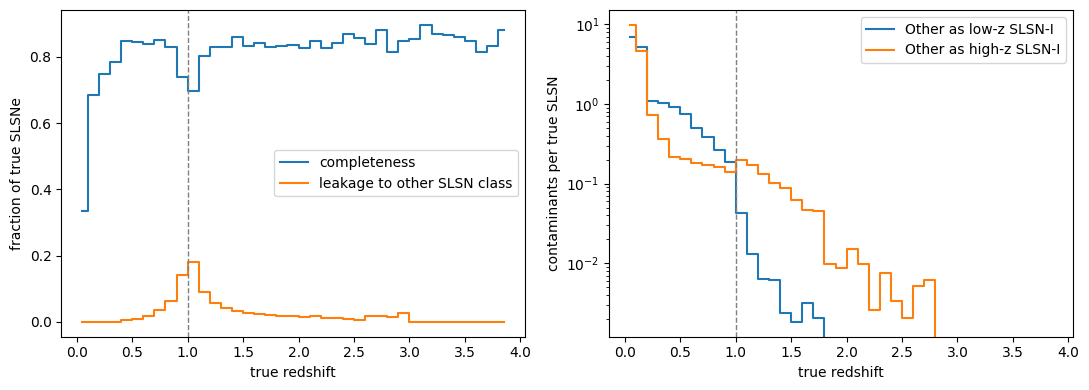

In [6]:
z_mid = (cm['z_low'] + cm['z_high']) / 2

fig, axs = plt.subplots(1, 2, figsize=(11, 4))

axs[0].step(z_mid[has_rates], (cm['f_lo_as_lo'] + cm['f_hi_as_hi'])[has_rates], where='mid', label='completeness')
axs[0].step(z_mid[has_rates], (cm['f_lo_as_hi'] + cm['f_hi_as_lo'])[has_rates], where='mid', label='leakage to other SLSN class')
axs[0].set_ylabel('fraction of true SLSNe')

axs[1].step(z_mid[has_rates], cm['c_oth_as_lo'][has_rates], where='mid', label='Other as low-z SLSN-I')
axs[1].step(z_mid[has_rates], cm['c_oth_as_hi'][has_rates], where='mid', label='Other as high-z SLSN-I')
axs[1].set_yscale('log')
axs[1].set_ylabel('contaminants per true SLSN')

for ax in axs:
    ax.axvline(1.0, color='gray', ls='--', lw=1)
    ax.set_xlabel('true redshift')
    ax.legend()
plt.tight_layout()
plt.show()

## Glue: what ORACLE would classify under each rate model

`P_hi = N_hi * f_hi_as_hi + N_lo * f_lo_as_hi + N_naive * c_oth_as_hi` (and the same for `P_lo`).

`N_lo` / `N_hi` are the model's counts in the bin (all of a bin's SLSNe are one class, split at z = 1).

In [7]:
elasticc_norm = 1.0   # k: ELAsTiCC SLSN rate / naive model rate (unverified)

is_hi = cm['z_low'] >= 1.0
glue = cm[['z_low', 'z_high']].copy()

for model in rate_files:
    N = rate_counts[f'N_{model}'].where(has_rates, 0)
    N_lo = N.where(~is_hi, 0)
    N_hi = N.where(is_hi, 0)
    N_fp_ref = elasticc_norm * rate_counts['N_naive'].where(has_rates, 0)

    for p in ['lo', 'hi']:
        tp = N_lo * cm[f'f_lo_as_{p}'] + N_hi * cm[f'f_hi_as_{p}']
        fp = N_fp_ref * cm[f'c_oth_as_{p}']
        glue[f'P_{p}_{model}'] = tp + fp
        glue[f'FP_{p}_{model}'] = fp

glue.to_csv('glue_by_z.csv', index=False)
glue

,z_low,z_high,P_lo_naive,FP_lo_naive,P_hi_naive,FP_hi_naive,P_lo_O,FP_lo_O,P_hi_O,FP_hi_O,P_lo_Fe,FP_lo_Fe,P_hi_Fe,FP_hi_Fe
0,0.0,0.1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.1,0.2,2114.842105,1867.157895,1657.578947,1657.578947,2157.947368,1867.157895,1657.578947,1657.578947,2147.000000,1867.157895,1657.578947,1657.578947
2,0.2,0.3,2032.771084,1203.614458,809.096386,809.096386,2035.759036,1203.614458,809.096386,809.096386,2049.951807,1203.614458,809.096386,809.096386
3,0.3,0.4,3969.911263,2240.593857,796.989761,796.989761,4000.525597,2240.593857,796.989761,796.989761,4249.365188,2240.593857,796.989761,796.989761
4,0.4,0.5,6765.896629,3533.015730,848.952809,823.226966,6838.755056,3533.015730,849.532584,823.226966,7563.950562,3533.015730,855.303371,823.226966
5,0.5,0.6,9278.429675,4360.502318,1231.729521,1186.775889,9388.336940,4360.502318,1232.734158,1186.775889,11058.927357,4360.502318,1248.004637,1186.775889
6,0.6,0.7,10829.946128,4037.360269,1618.581369,1463.997755,10970.794613,4037.360269,1621.786756,1463.997755,13707.279461,4037.360269,1684.062851,1463.997755
7,0.7,0.8,12891.305085,4012.590395,2177.983051,1795.364407,13336.987759,4012.590395,2197.189266,1795.364407,18053.725047,4012.590395,2400.451977,1795.364407
8,0.8,0.9,14290.652666,3443.276252,2946.852989,2133.563813,14932.735057,3443.276252,2994.993538,2133.563813,21550.165590,3443.276252,3491.139742,2133.563813
9,0.9,1.0,14094.803685,2859.971651,4316.938342,2158.469171,15242.781006,2859.971651,4537.491141,2158.469171,23615.047484,2859.971651,6145.995748,2158.469171


In [8]:
# Poisson errors only: summed over all redshift bins, the variance of each P is P itself
results = []
for model in rate_files:
    P_lo = glue[f'P_lo_{model}'].sum()
    P_hi = glue[f'P_hi_{model}'].sum()
    R = P_hi / P_lo
    sigma_R = R * np.sqrt(1 / P_hi + 1 / P_lo)
    results.append({
        'model': model,
        'P_lo': P_lo,
        'P_hi': P_hi,
        'FP fraction (lo)': glue[f'FP_lo_{model}'].sum() / P_lo,
        'FP fraction (hi)': glue[f'FP_hi_{model}'].sum() / P_hi,
        'R': R,
        'sigma_R': sigma_R,
    })

results = pd.DataFrame(results).set_index('model')
results

,P_lo,P_hi,FP fraction (lo),FP fraction (hi),R,sigma_R
model,,,,,,
naive,87245.699162,214323.080258,0.331725,0.134441,2.456546,0.009865
O,93986.451558,366365.543196,0.307933,0.078648,3.898068,0.014253
Fe,131481.581026,717196.327351,0.220119,0.040176,5.454729,0.016364


In [9]:
# Separation after 10 years, and time to 5 sigma assuming sigma ~ 1/sqrt(t)
survey_days = 10 * 365.25
pairs = [('Fe', 'naive'), ('O', 'naive'), ('Fe', 'O')]

for a, b in pairs:
    n_sigma = abs(results.loc[a, 'R'] - results.loc[b, 'R']) / np.hypot(results.loc[a, 'sigma_R'], results.loc[b, 'sigma_R'])
    days = survey_days * (5 / n_sigma) ** 2
    print(f'{a} vs {b}: {n_sigma:.0f} sigma in 10 yr, 5 sigma after {days:.1f} days')

Fe vs naive: 157 sigma in 10 yr, 5 sigma after 3.7 days
O vs naive: 83 sigma in 10 yr, 5 sigma after 13.2 days
Fe vs O: 72 sigma in 10 yr, 5 sigma after 17.7 days


## Time to 5σ for any precision and recall

A simple classifier model, applied separately to the z < 1 and z ≥ 1 classes:

* `P = recall * N_model + FP`
* `FP = recall * N_naive * (1 - precision) / precision`, i.e. **precision is defined under the naive model**, and the FP count is then held fixed for O and Fe.

Errors are Poisson, plus an optional fractional systematic `fp_sys` on the FP counts that does not shrink with time
(shared by all models, so it enters only through how differently it moves each model's R). With `fp_sys > 0`, 5σ may never be reached (returned as `inf`).

Times are survey days: ORACLE classifies an object `classification_delay` = 64 days after trigger, so counts only start accumulating then. Completeness and purity are the 64-day values.

In [10]:
survey_days = 10 * 365.25
classification_delay = 64     # days after trigger at which ORACLE classifies (64-day classifications)

# 10-yr counts per model in each class, from all of Christina's bins (no test-set rates needed here)
z_split = rate_counts['z_low'] >= 1.0
N_class = {model: {'lo': rate_counts.loc[~z_split, f'N_{model}'].sum(),
                   'hi': rate_counts.loc[z_split, f'N_{model}'].sum()}
           for model in rate_files}


def ratio_and_errors(model, recall_lo, precision_lo, recall_hi, precision_hi):
    # R = P_hi / P_lo, its 10-yr Poisson error, and dR/dFP for the FP systematic
    P, FP = {}, {}
    for c, r, p in [('lo', recall_lo, precision_lo), ('hi', recall_hi, precision_hi)]:
        FP[c] = r * N_class['naive'][c] * (1 - p) / p
        P[c] = r * N_class[model][c] + FP[c]
    R = P['hi'] / P['lo']
    sigma_stat = R * np.sqrt(1 / P['hi'] + 1 / P['lo'])
    # shift in R if both FP counts move up by fp_sys (fully correlated)
    dR_dfrac = FP['hi'] / P['lo'] - R * FP['lo'] / P['lo']
    return R, sigma_stat, dR_dfrac


def days_to_5sigma(model_a, model_b, recall_lo, precision_lo, recall_hi=None, precision_hi=None, fp_sys=0.0, n_sigma=5):
    # Same precision / recall for both classes unless the high-z values are given
    recall_hi = recall_lo if recall_hi is None else recall_hi
    precision_hi = precision_lo if precision_hi is None else precision_hi

    R_a, stat_a, d_a = ratio_and_errors(model_a, recall_lo, precision_lo, recall_hi, precision_hi)
    R_b, stat_b, d_b = ratio_and_errors(model_b, recall_lo, precision_lo, recall_hi, precision_hi)

    delta = np.abs(R_a - R_b)
    stat2 = stat_a**2 + stat_b**2               # at 10 yr, scales as 1/t
    sys2 = (fp_sys * (d_a - d_b))**2            # does not scale with t
    margin = (delta / n_sigma)**2 - sys2
    # time spent accumulating classifications, plus the wait before the first ones arrive
    return classification_delay + np.where(margin > 0, survey_days * stat2 / np.where(margin > 0, margin, 1), np.inf)

In [11]:
# ORACLE's effective values in this setup (naive model, from the per-bin confusion matrix above)
oracle = {}
for c, is_c in [('lo', ~is_hi), ('hi', is_hi)]:
    N = rate_counts['N_naive'].where(has_rates & is_c, 0)
    tp = (N * cm[f'f_{c}_as_{c}']).sum()
    oracle[f'recall_{c}'] = tp / N.sum()
    oracle[f'precision_{c}'] = tp / glue[f'P_{c}_naive'].sum()
oracle

{'recall_lo': np.float64(0.8100456570356482),
 'precision_lo': np.float64(0.5583137732017133),
 'recall_hi': np.float64(0.8242366661229984),
 'precision_hi': np.float64(0.8488569589010612)}

In [12]:
# Try any numbers here
scenarios = {
    'perfect':           dict(recall_lo=1.0, precision_lo=1.0),
    'ORACLE (64 d)':     dict(**oracle),
    'ORACLE, 10% FP sys': dict(**oracle, fp_sys=0.10),
    'recall 0.5, precision 0.5': dict(recall_lo=0.5, precision_lo=0.5),
    'recall 0.5, precision 0.5, 10% FP sys': dict(recall_lo=0.5, precision_lo=0.5, fp_sys=0.10),
}

table = pd.DataFrame({
    name: {f'{a} vs {b}': float(days_to_5sigma(a, b, **kw)) for a, b in pairs}
    for name, kw in scenarios.items()
}).T
table.round(1)

,Fe vs naive,O vs naive,Fe vs O
perfect,68.3,77.0,91.3
ORACLE (64 d),67.2,75.6,76.5
"ORACLE, 10% FP sys",67.3,76.2,76.7
"recall 0.5, precision 0.5",73.3,101.6,101.4
"recall 0.5, precision 0.5, 10% FP sys",73.7,104.0,102.3


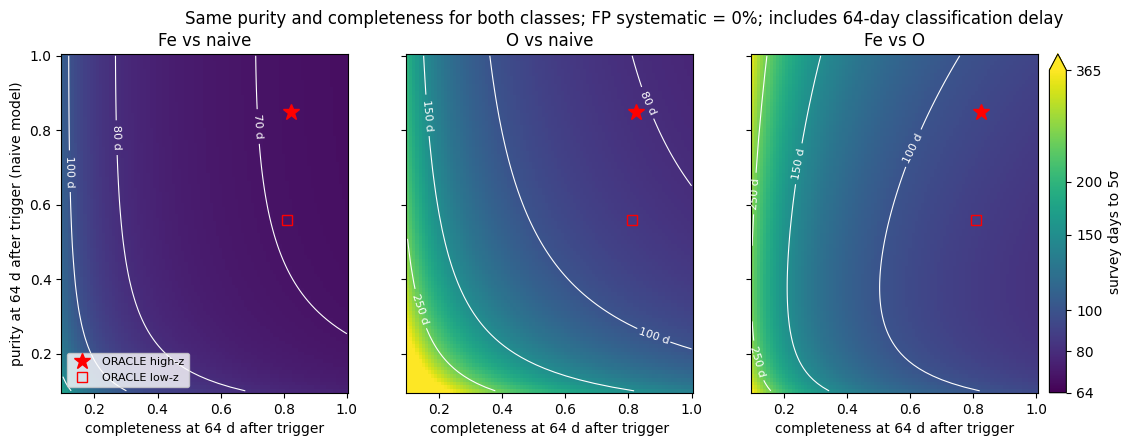

In [13]:
recall_grid = np.linspace(0.1, 1.0, 91)
precision_grid = np.linspace(0.1, 1.0, 91)
RR, PP = np.meshgrid(recall_grid, precision_grid)

fp_sys = 0.0                      # set > 0 to include an FP systematic
max_days = 365                    # colour scale saturates here
contour_days = [70, 80, 100, 150, 250]

fig, axs = plt.subplots(1, len(pairs), figsize=(5 * len(pairs), 4.4), sharey=True)
for ax, (a, b) in zip(axs, pairs):
    days = days_to_5sigma(a, b, RR, PP, fp_sys=fp_sys)
    log_days = np.log10(np.where(np.isfinite(days), days, np.nan))
    im = ax.pcolormesh(RR, PP, log_days, shading='auto', cmap='viridis', vmin=np.log10(classification_delay), vmax=np.log10(max_days))
    cs = ax.contour(RR, PP, days, levels=contour_days, colors='white', linewidths=0.8)
    ax.clabel(cs, fmt=lambda d: f'{d:g} d', fontsize=8)
    if fp_sys > 0:
        ax.contourf(RR, PP, ~np.isfinite(days), levels=[0.5, 1.5], colors='none', hatches=['//'])

    ax.plot(oracle['recall_hi'], oracle['precision_hi'], 'r*', ms=12, label='ORACLE high-z')
    ax.plot(oracle['recall_lo'], oracle['precision_lo'], 'rs', ms=7, mfc='none', label='ORACLE low-z')
    ax.set_title(f'{a} vs {b}')
    ax.set_xlabel(f'completeness at {classification_delay} d after trigger')
axs[0].set_ylabel(f'purity at {classification_delay} d after trigger (naive model)')
axs[0].legend(loc='lower left', fontsize=8)

cbar = fig.colorbar(im, ax=axs, pad=0.01, extend='max')
cbar.set_label('survey days to 5σ')
ticks = [64, 80, 100, 150, 200, 365]
cbar.set_ticks(np.log10(ticks))
cbar.set_ticklabels([str(t) for t in ticks])

fig.suptitle(f'Same purity and completeness for both classes; FP systematic = {fp_sys:.0%}; includes {classification_delay}-day classification delay')
plt.savefig('days_to_5sigma_precision_recall.pdf', bbox_inches='tight')
plt.show()

## ORACLE positives vs survey duration

Counts grow linearly with time (steady detection rate). ORACLE needs `classification_delay` days of light curve before an object is counted,
so the curves start after that. Bands are ±1σ Poisson.

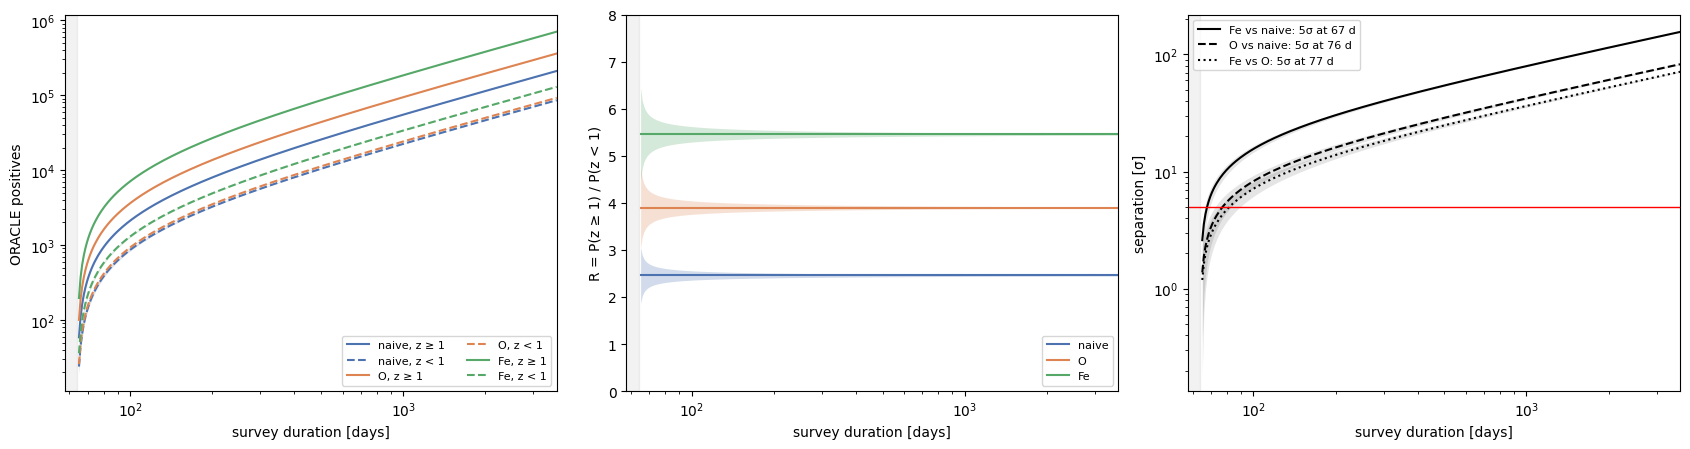

In [14]:
t_days = np.logspace(np.log10(classification_delay + 1), np.log10(survey_days), 300)
frac = (t_days - classification_delay) / survey_days

model_colors = {'naive': '#4C72B0', 'O': '#DD8452', 'Fe': '#55A868'}

fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))

for model, color in model_colors.items():
    for c, ls in [('hi', '-'), ('lo', '--')]:
        P_t = glue[f'P_{c}_{model}'].sum() * frac
        axs[0].plot(t_days, P_t, color=color, ls=ls, label=f'{model}, {"z ≥ 1" if c == "hi" else "z < 1"}')
        axs[0].fill_between(t_days, P_t - np.sqrt(P_t), P_t + np.sqrt(P_t), color=color, alpha=0.2, lw=0)

    R = results.loc[model, 'R']
    sigma_R_t = results.loc[model, 'sigma_R'] / np.sqrt(frac)
    axs[1].plot(t_days, np.full_like(t_days, R), color=color, label=model)
    axs[1].fill_between(t_days, R - sigma_R_t, R + sigma_R_t, color=color, alpha=0.25, lw=0)

# Separation between each pair of models vs time (ORACLE, Poisson only)
pair_styles = ['-', '--', ':']
for (a, b), ls in zip(pairs, pair_styles):
    n_sigma_t = np.abs(results.loc[a, 'R'] - results.loc[b, 'R']) / np.hypot(results.loc[a, 'sigma_R'], results.loc[b, 'sigma_R']) * np.sqrt(frac)
    t5 = float(days_to_5sigma(a, b, **oracle))
    axs[2].plot(t_days, n_sigma_t, color='k', ls=ls, label=f'{a} vs {b}: 5σ at {t5:.0f} d')
    # a measured separation scatters by ±1 around its expected value
    axs[2].fill_between(t_days, np.clip(n_sigma_t - 1, 0.1, None), n_sigma_t + 1, color='k', alpha=0.1, lw=0)
axs[2].axhline(5, color='red', lw=1)
axs[2].set_xscale('log')
axs[2].set_yscale('log')
axs[2].set_ylabel('separation [σ]')
axs[2].legend(fontsize=8, loc='upper left')

axs[0].set_xscale('log')
axs[0].set_yscale('log')
axs[0].set_ylabel('ORACLE positives')
axs[0].legend(fontsize=8, ncol=2)

axs[1].set_xscale('log')
axs[1].set_ylim(0, 8)
axs[1].set_ylabel('R = P(z ≥ 1) / P(z < 1)')
axs[1].legend(fontsize=8, loc='lower right')

for ax in axs:
    ax.set_xlabel('survey duration [days]')
    ax.axvspan(0, classification_delay, color='gray', alpha=0.1)
    ax.set_xlim(classification_delay * 0.9, survey_days)

plt.tight_layout()
plt.savefig('oracle_positives_vs_time.pdf', bbox_inches='tight')
plt.show()